# Page: three ways to vary a scene instance (RPGM maps)

**The fact behind all of it:** an instance in the map is a reference to the base `.tscn` plus a list of overrides saved in the map file. The film-clapper icon always opens the **base**, so saving there changes every instance. There is no "go into this instance" mode.

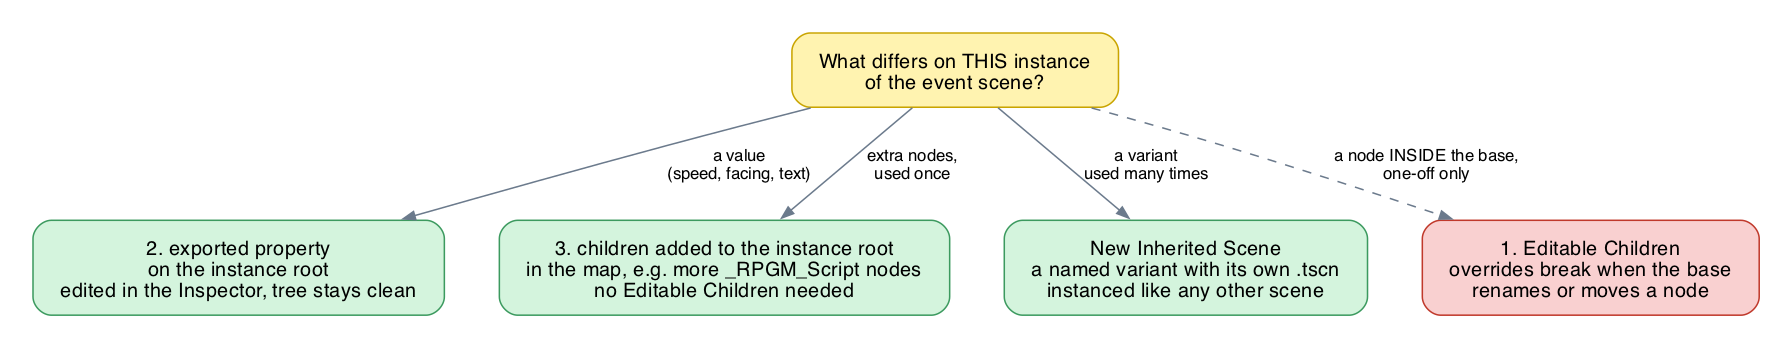

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=11];
  ask     [label="What differs on THIS instance\nof the event scene?", fillcolor="#fff3b0", color="#c9a400"];
  export  [label="2. exported property\non the instance root\nedited in the Inspector, tree stays clean", fillcolor="#d4f4dd", color="#3c9a5f"];
  child   [label="3. children added to the instance root\nin the map, e.g. more _RPGM_Script nodes\nno Editable Children needed", fillcolor="#d4f4dd", color="#3c9a5f"];
  inherit [label="New Inherited Scene\na named variant with its own .tscn\ninstanced like any other scene", fillcolor="#d4f4dd", color="#3c9a5f"];
  edit    [label="1. Editable Children\noverrides break when the base\nrenames or moves a node", fillcolor="#f9d0d0", color="#c0392b"];
  ask -> export  [label="a value\n(speed, facing, text)"];
  ask -> child   [label="extra nodes,\nused once"];
  ask -> inherit [label="a variant\nused many times"];
  ask -> edit    [label="a node INSIDE the base,\none-off only", style=dashed];
}
```

</details>

| | 1. Editable Children | 2. Exported properties | 3. Children added on the map |
|---|---|---|---|
| What you change | nodes inside the base | values on the instance root | new nodes under the instance root |
| Saved in | the map `.tscn` | the map `.tscn` | the map `.tscn` |
| Affects the base | no | no | no |
| Map tree | whole subtree exposed | nothing extra | the added nodes show |
| Breaks when the base changes | yes, on rename or move | only if the export is removed | no |
| Godot's view | escape hatch | **the intended interface** | normal for one-off content |
| Fits `_RPGM_Event` today | works, but fragile | yes, for values (`speed`, `facing`, `map_position`) | yes, for extra `_RPGM_Script` nodes |
| **Recommendation** | **avoid as a workflow** | **default for values** | **default for scripts, for now** |

**What I recommend for the RPGM maps**

- **Now, with no code changes:** exports (2) for anything that is a value, and children added on the map (3) for an event's scripts. You can add several `_RPGM_Script` nodes to an `_RPGM_Event` instance without turning on Editable Children.
- **A variant placed more than a couple of times:** make it a New Inherited Scene (right-click the base in FileSystem) and instance that, so the map tree shows one node instead of a repeated subtree.
- **Editable Children (1):** keep for a genuine one-off tweak, not as the way maps are authored.
- **One scene per map, not a mono-map:** Godot expects the world split into map scenes; a large tree per map is normal and folding is the only native relief.
- **Later, if the tree clutter still hurts:** move script content from nodes to data, an exported array of Resources on `_RPGM_Event` edited in the Inspector. That is a real refactor (`_RPGM_Script` extends `_RPGM_Node` today), and it is the direction the v3 RPGM plugin's command editor already points.

Not run in the editor: this is from how Godot scene instancing works, checked only against the class headers of `_rpgm_event.gd` and `_rpgm_script.gd`.
